# Day 7: Week 1 Mini Project
## Netflix Movies and TV Shows Analysis

### Objective
Analyze the Netflix dataset to understand content types, ratings, release trends, and popular genres.

### Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

### Project Workflow
1. Load the dataset
2. Explore and clean the data
3. Perform data analysis
4. Create four visualizations
5. Document key insights and conclusions

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

df = pd.read_csv("netflix_titles.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'netflix_titles.csv'

In [2]:
import os

print("Current working folder:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

Current working folder:
c:\Users\sunid\OneDrive\Desktop\internships\AI-ML-Internship

Files in this folder:
['.git', 'data_visualization.ipynb', 'hello.py', 'netflix_analysis.ipynb', 'numpy_practice.ipynb', 'numpy_practice.py', 'online_sales.csv', 'pandas_practice.ipynb', 'python_practice.py', 'README.md', 'simple_calculator.py', 'students.txt', 'student_grade_calculator.py', 'student_marks_analysis.py', 'student_record_management.py']


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

df = pd.read_csv("netflix_titles.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [4]:
# Display all column names
print("Column names:")
print(df.columns.tolist())

# Check dataset information
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values in each column:")
display(df.isnull().sum())

# Check duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Display statistical summary
display(df.describe(include="all").T)

Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB

Missing values in each column:


show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


Number of duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8807,8807,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Dick Johnson Is Dead,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6173,4528,Rajiv Chilaka,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7982,7692,David Attenborough,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7976,748,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,1767,"January 1, 2020",109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8803,17,TV-MA,3207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
# Create a copy so the original data stays unchanged
df_clean = df.copy()

# Remove duplicate rows, if any
df_clean = df_clean.drop_duplicates()

# Remove extra spaces from text columns
text_cols = df_clean.select_dtypes(include="object").columns

for col in text_cols:
    df_clean[col] = df_clean[col].apply(
        lambda value: value.strip() if isinstance(value, str) else value
    )

# Fill missing descriptive information with "Unknown"
for col in ["director", "cast", "country"]:
    df_clean[col] = df_clean[col].fillna("Unknown")

# Convert date_added to a proper date format
df_clean["date_added"] = pd.to_datetime(
    df_clean["date_added"],
    errors="coerce"
)

print("Original rows:", len(df))
print("Rows after cleaning:", len(df_clean))

print("\nMissing values after cleaning:")
display(df_clean.isnull().sum())

Original rows: 8807
Rows after cleaning: 8807

Missing values after cleaning:


C:\Users\sunid\AppData\Local\Temp\ipykernel_19696\1085525623.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_cols = df_clean.select_dtypes(include="object").columns


show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           4
duration         3
listed_in        0
description      0
dtype: int64

Content type counts:


type
Movie      6131
TV Show    2676
Name: count, dtype: int64

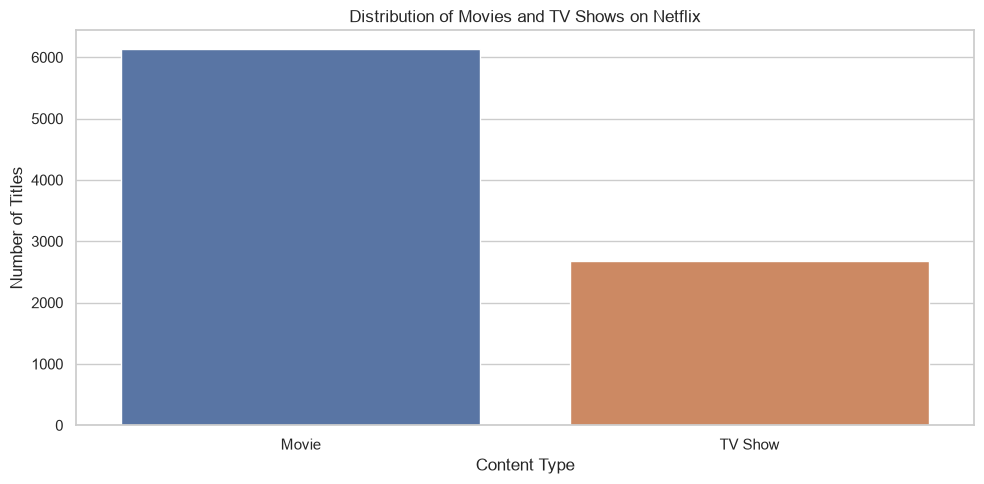

In [6]:
# Count Movies and TV Shows
content_counts = df_clean["type"].value_counts()

print("Content type counts:")
display(content_counts)

# Create the bar chart
sns.countplot(data=df_clean, x="type", hue="type", legend=False)

plt.title("Distribution of Movies and TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

Titles added by year:


date_added_year
2008       2
2009       2
2010       1
2011      13
2012       3
2013      11
2014      24
2015      82
2016     429
2017    1188
2018    1649
2019    2016
2020    1879
2021    1498
Name: count, dtype: int64

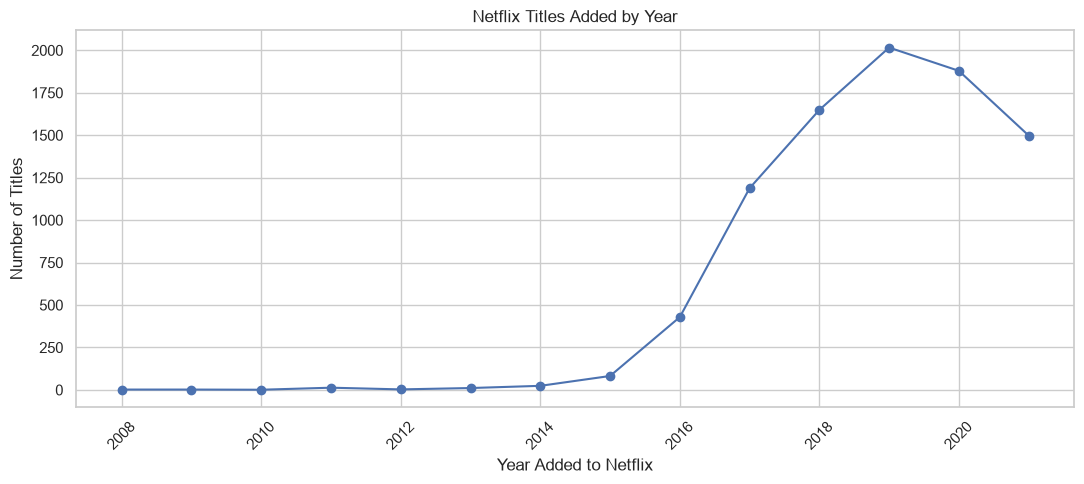

In [7]:
# Extract the year from the date_added column
df_clean["date_added_year"] = df_clean["date_added"].dt.year

# Count titles added each year
added_by_year = (
    df_clean["date_added_year"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

print("Titles added by year:")
display(added_by_year)

# Create a line chart
plt.figure(figsize=(11, 5))
plt.plot(added_by_year.index, added_by_year.values, marker="o")

plt.title("Netflix Titles Added by Year")
plt.xlabel("Year Added to Netflix")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top 10 content ratings:


rating
TV-MA    3207
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: count, dtype: int64

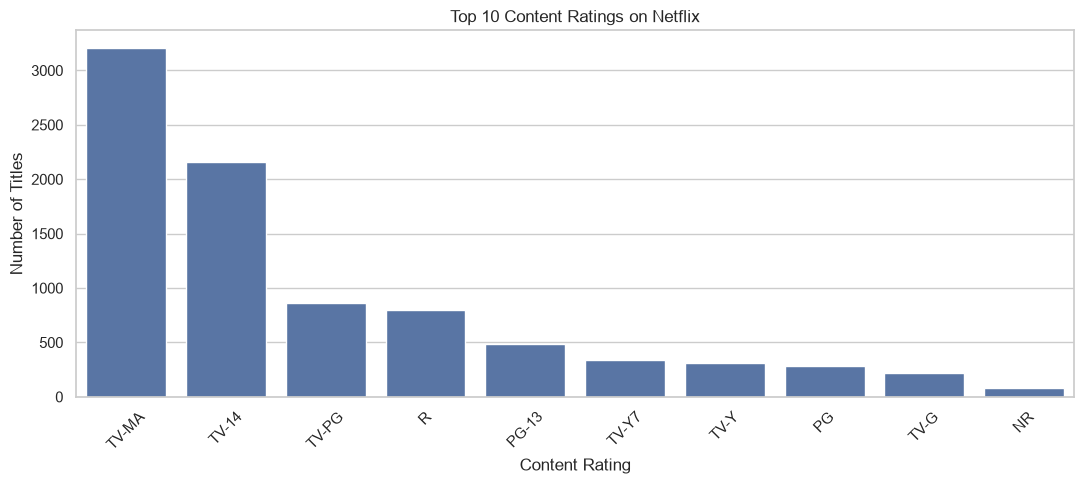

In [8]:
# Count the 10 most common content ratings
rating_counts = (
    df_clean["rating"]
    .fillna("Unknown")
    .value_counts()
    .head(10)
)

print("Top 10 content ratings:")
display(rating_counts)

# Create a bar chart
plt.figure(figsize=(11, 5))
sns.barplot(x=rating_counts.index, y=rating_counts.values)

plt.title("Top 10 Content Ratings on Netflix")
plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Top 10 genres:


listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

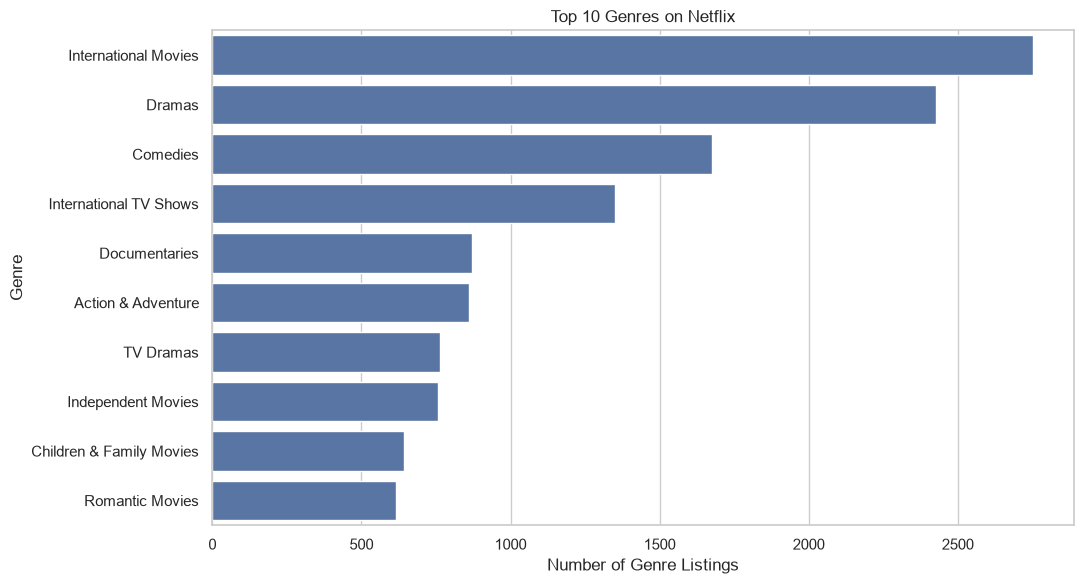

In [9]:
# Split genre lists and count each genre
genre_counts = (
    df_clean["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
    .value_counts()
    .head(10)
)

print("Top 10 genres:")
display(genre_counts)

# Create a horizontal bar chart
plt.figure(figsize=(11, 6))
sns.barplot(x=genre_counts.values, y=genre_counts.index)

plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of Genre Listings")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

In [10]:
# 1. Total titles
print("Total titles:", len(df_clean))

# 2. Movies vs TV Shows
print("\nContent type percentages:")
display(
    (df_clean["type"].value_counts(normalize=True) * 100).round(2)
)

# 3. Most common release years
print("\nTop 5 release years:")
display(df_clean["release_year"].value_counts().head(5))

# 4. Most common ratings
print("\nTop 5 content ratings:")
display(df_clean["rating"].fillna("Unknown").value_counts().head(5))

# 5. Most common genres
print("\nTop 5 genres:")
display(genre_counts.head(5))

# 6. Most common countries
country_counts = (
    df_clean["country"]
    .str.split(", ")
    .explode()
    .value_counts()
)

print("\nTop 5 countries:")
display(country_counts.head(5))

# 7. Year with the most recorded additions
print("\nYear with the most recorded additions:")
if not added_by_year.empty:
    print(int(added_by_year.idxmax()))
    print("Number of titles:", int(added_by_year.max()))

Total titles: 8807

Content type percentages:


type
Movie      69.62
TV Show    30.38
Name: proportion, dtype: float64


Top 5 release years:


release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902
Name: count, dtype: int64


Top 5 content ratings:


...


Top 5 genres:


listed_in
International Movies      2752
Dramas                    2427
Comedies                  1674
International TV Shows    1351
Documentaries              869
Name: count, dtype: int64


Top 5 countries:


country
United States     3689
India             1046
Unknown            831
United Kingdom     804
Canada             445
Name: count, dtype: int64


Year with the most recorded additions:
2019
Number of titles: 2016


In [12]:
print("Top 5 genres:")
display(genre_counts.head(5))

print("Top 5 release years:")
display(df_clean["release_year"].value_counts().head(5))

print("Top 5 countries:")
display(country_counts.head(5))

Top 5 genres:


listed_in
International Movies      2752
Dramas                    2427
Comedies                  1674
International TV Shows    1351
Documentaries              869
Name: count, dtype: int64

Top 5 release years:


release_year
2018    1147
2017    1032
2019    1030
2020     953
2016     902
Name: count, dtype: int64

Top 5 countries:


country
United States     3689
India             1046
Unknown            831
United Kingdom     804
Canada             445
Name: count, dtype: int64

## Key Insights

1. **Content type:** The dataset contains 6,131 movies and 2,676 TV shows. Movies make up approximately 69.6% of all titles, while TV shows account for 30.4%.

2. **Content additions:** The highest number of recorded Netflix additions occurred in 2019, with 2,016 titles.

3. **Content ratings:** TV-MA is the most common rating, with 3,207 titles, followed by TV-14 with 2,160 titles.

4. **Popular genres:** International Movies is the most frequent genre listing, with 2,752 entries, followed by Dramas with 2,427 entries.

5. **Release trends:** 2018 is the most frequent release year in this dataset, with 1,147 titles, followed by 2017 with 1,032 titles.

6. **Country representation:** The United States appears most frequently in the country data, with 3,689 titles, followed by India with 1,046 titles.

7. **Data quality:** The original dataset had missing values in director (2,634), cast (825), country (831), date_added (10), rating (4), and duration (3). Missing director, cast, and country values were filled with "Unknown". The dataset contained no duplicate rows.

8. **Conclusion:** The dataset contains substantially more movies than TV shows. The visualizations reveal patterns in content ratings, genre listings, release years, and recorded additions.



## Conclusion

This project explored a Netflix Movies and TV Shows dataset using Python, Pandas, Matplotlib, and Seaborn.

The analysis included data inspection, cleaning, and four visualizations covering content types, yearly additions, content ratings, and popular genres.

The project helped identify patterns in the dataset and practice exploratory data analysis using real-world data.

The findings reflect the available dataset snapshot and should not be interpreted as a complete representation of Netflix's current catalog.